<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h1>Riding the Demand Curve</h1>
<h3>Hourly Bike Rental Forecasting and Demand Drivers for Cook County</h3>

<strong>Prepared for:</strong> Cook County Planning and Development Department<br>
<strong>Prepared by:</strong> Seyha Seng<br>
<strong>Course:</strong> DAT-7470 Business Analysis with Structured Data - Final Assignment<br>
Hult International Business School<br>
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h2>Analysis Introduction</h2>

* Cook County asked us to predict how many bikes are rented in an hour and to explain what drives this demand, so that bikes are available when residents need them.
* Chicago's bike-share system, Divvy, has already been studied, and its member trips are strongly associated with weekday morning and afternoon commuting periods (Lu et al., 2026, Abstract).
* Getting demand right matters in both directions: too few bikes at busy times means lost trips, while maintenance at busy times removes bikes exactly when riders need them.
* The data contains 678 hours from March to June, and each hour records the time, day, month, holiday flag, weather and number of rentals.
* Demand changes sharply from hour to hour, ranging from 9 to 3,734 rentals with an average of 952. Because the file has hours but no full dates, we predict rentals for one hour rather than for a whole day.
* To support the client, we answer three questions: why people rent bikes, which weather factor matters most, and when demand is low enough for maintenance. We then choose the model with the highest test R-square among the models whose train-test gap is 0.05 or less.
* Our main findings are that demand follows the work commute, temperature is the most important weather factor, and cool nights from 2 to 6 am are the quietest time, while the final linear model explains about 83% of the variation in rentals on hours it had not seen before.
* Since the data covers only spring and early summer, these results should be checked again once data from the rest of the year is available.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part I: Setup</h2>
<h4>Imports</h4>

In [1]:
# importing libraries
import pandas as pd                                  # data science essentials
import numpy as np                                   # mathematical essentials
import matplotlib.pyplot as plt                      # data visualization
import seaborn as sns                                # enhanced data visualization
from sklearn.model_selection import train_test_split # train-test split
from sklearn.linear_model import LinearRegression    # linear regression
from sklearn.tree import DecisionTreeRegressor       # regression trees
from sklearn.tree import plot_tree                   # tree plots
from sklearn.preprocessing import StandardScaler     # standard scaler

<h4>Loading the Dataset</h4>Keep <code>bike_rentals.xlsx</code> in the same folder as this notebook.

In [2]:
# specifying the file name
file = './bike_rentals.xlsx'


# reading the file into Python
bikes = pd.read_excel(io = file)


# checking the first five rows
bikes.head(n = 5)

,ID,Month,Day of Week,Hour,Temperature,Humidity,Wind Speed,Visibility,Dew Point Temperature,UV Index,Rainfall,Snowfall,Seasons,Holiday,RENTALS
0,1,Mar,Wednesday,1,2.1,97,0.2,859,1.6,0.00,0.0,0,Spring,Yes,158
1,2,Mar,Wednesday,2,2.0,97,1.0,580,1.5,0.00,0.0,0,Spring,Yes,191
2,3,Mar,Wednesday,4,1.6,97,1.1,636,1.1,0.00,0.0,0,Spring,Yes,31
3,4,Mar,Wednesday,5,2.2,97,2.9,362,1.7,0.00,0.0,0,Spring,Yes,12
4,5,Mar,Wednesday,12,0.5,46,4.7,1172,-9.8,2.49,0.0,0,Spring,Yes,333


<h4>User-Defined Function</h4>This function applies the model building framework from class (split, fit, score) with the same settings for every model.

In [3]:
########################################
# run_model
########################################
def run_model(model, x_data, y_data, model_name):
    """
    Splits the data, fits the model on the training set and scores it.

    PARAMETERS
    ----------
    model      : unfitted LinearRegression() or DecisionTreeRegressor()
    x_data     : x-features
    y_data     : y-variable
    model_name : name of the model for the comparison table
    """

    # train-test split (course settings)
    x_train, x_test, y_train, y_test = train_test_split(x_data,
                                                        y_data,
                                                        test_size    = 0.35,
                                                        random_state = 702)


    # FITTING to the training data
    model.fit(x_train, y_train)


    # SCORING the results (R-square)
    train_score = model.score(x_train, y_train)
    test_score  = model.score(x_test, y_test)


    # one row for the comparison table
    return {'Model'          : model_name,
            'Training R2'    : round(train_score, 4),
            'Testing R2'     : round(test_score, 4),
            'Train-Test Gap' : round(abs(train_score - test_score), 4)}

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part II: Data Audit</h2>

In [4]:
# size and completeness of the data
print(f"Rows (hours)             : {bikes.shape[0]}")
print(f"Missing values           : {bikes.isnull().sum().sum()}")
print(f"Duplicate rows (no ID)   : {bikes.drop(columns = 'ID').duplicated().sum()}")
print(f"Months covered           : {bikes['Month'].unique().tolist()}")


# ranges of rentals and temperature
print(f"Rentals per hour         : min {bikes['RENTALS'].min()}, median {bikes['RENTALS'].median():.0f}, "
      f"mean {bikes['RENTALS'].mean():.0f}, max {bikes['RENTALS'].max()}")
print(f"Temperature range        : {bikes['Temperature'].min()} to {bikes['Temperature'].max()}")


# values to check with the client
print(f"Snowfall values          : {bikes['Snowfall'].unique().tolist()}")
print(f"Hours with rain          : {(bikes['Rainfall'] > 0).sum()}")
print(f"Two largest Rainfall     : {bikes['Rainfall'].nlargest(2).tolist()}")
print(f"Hours with 0% humidity   : {(bikes['Humidity'] == 0).sum()}")


# more values to check: UV Index, visibility cap and holiday days
print(f"Maximum UV Index         : {bikes['UV Index'].max()}")
print(f"Hours at visibility 2000 : {(bikes['Visibility'] == 2000).sum()}")
holidays = bikes.loc[bikes['Holiday'] == 'Yes', 'Month'] + ' ' + bikes.loc[bikes['Holiday'] == 'Yes', 'Day of Week']
print(f"Holiday months and days  : {holidays.unique().tolist()}")

Rows (hours)             : 678
Missing values           : 0
Duplicate rows (no ID)   : 0
Months covered           : ['Mar', 'Apr', 'May', 'June']
Rentals per hour         : min 9, median 780, mean 952, max 3734
Temperature range        : -6.6 to 32.7
Snowfall values          : [0]
Hours with rain          : 60
Two largest Rainfall     : [35.0, 5.4]
Hours with 0% humidity   : 1
Maximum UV Index         : 3.39
Hours at visibility 2000 : 116
Holiday months and days  : ['Mar Wednesday', 'May Monday', 'June Tuesday']


**What the data audit shows**

* The data is complete: all 678 hours have a value in every column, and there are no duplicate rows.
* Rentals range from 9 to 3,734 per hour, and the mean (952) sits above the median (780) because a few very busy hours pull it upward.
* Two columns are left out of every model: Snowfall is always 0, so it cannot explain any change in rentals, and ID is only a row number that a planner would not know in advance.
* The file does not state any units, although the temperatures (-6.6 to 32.7) are consistent with degrees Celsius.
* Several values should be confirmed with the client before the model is used: one hour shows 0% humidity, the "UV Index" never rises above 3.39, and 116 hours have a visibility of exactly 2,000.
* The holiday coding also needs checking, because a Wednesday in March is marked as a holiday even though there is no U.S. federal holiday in March.
* Finally, one hour records Rainfall of 35, far above the next highest value of 5.4, so results that depend on the rainfall amount should be read with care.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part III: Feature Engineering</h2>
All new features are yes/no flags or categories made from existing columns. None of them uses RENTALS, powers or roots.

In [5]:
# day type: 1 = weekend or holiday (off-day), 0 = working day
bikes['holiday'] = 0
bikes.loc[bikes['Holiday'] == 'Yes', 'holiday'] = 1

bikes['offday'] = 0
bikes.loc[bikes['Day of Week'].isin(['Saturday', 'Sunday']), 'offday'] = 1
bikes.loc[bikes['holiday'] == 1, 'offday'] = 1


# readable day type for charts and tables
bikes['day_type'] = 'Working day'
bikes.loc[bikes['offday'] == 1, 'day_type'] = 'Weekend / Holiday'


# commute flags: working-day rush hours, the 8 am peak and the 5-7 pm peak
bikes['rush'] = 0
bikes.loc[(bikes['offday'] == 0) & (bikes['Hour'].isin([7, 8, 9, 17, 18, 19])), 'rush'] = 1

bikes['am_peak'] = 0
bikes.loc[(bikes['offday'] == 0) & (bikes['Hour'] == 8), 'am_peak'] = 1

bikes['pm_peak'] = 0
bikes.loc[(bikes['offday'] == 0) & (bikes['Hour'].isin([17, 18, 19])), 'pm_peak'] = 1


# weather flags: any rain, very humid hours and pleasant evenings (15 or warmer, 4 pm to 10:59 pm)
bikes['rain'] = 0
bikes.loc[bikes['Rainfall'] > 0, 'rain'] = 1

bikes['humid_high'] = 0
bikes.loc[bikes['Humidity'] >= 80, 'humid_high'] = 1

bikes['pleasant_evening'] = 0
bikes.loc[(bikes['Temperature'] >= 15) & (bikes['Hour'] >= 16) & (bikes['Hour'] <= 22), 'pleasant_evening'] = 1


# month as a number for the regression tree (March = 3 ... June = 6)
bikes['month_num'] = bikes['Month'].map({'Mar' : 3, 'Apr' : 4, 'May' : 5, 'June' : 6})

In [6]:
# one hot encoding hour and month for the linear models
hour_dummies  = pd.get_dummies(data = bikes['Hour'],  prefix = 'hour',  dtype = int)
month_dummies = pd.get_dummies(data = bikes['Month'], prefix = 'month', dtype = int)


# dropping one category from each (midnight and March become the baseline)
hour_dummies  = hour_dummies.drop(labels = 'hour_0', axis = 1)
month_dummies = month_dummies.drop(labels = 'month_Mar', axis = 1)


# weather columns (Snowfall is always 0, so it is not used)
weather = ['Temperature', 'Humidity', 'Wind Speed', 'Visibility', 'UV Index', 'Rainfall']


# y-variable
y_rentals = bikes['RENTALS']

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part IV: Task 1 - Leisure, Exercise or Commuting?</h2>
We compare working days with weekends and holidays at the same hours of the day.

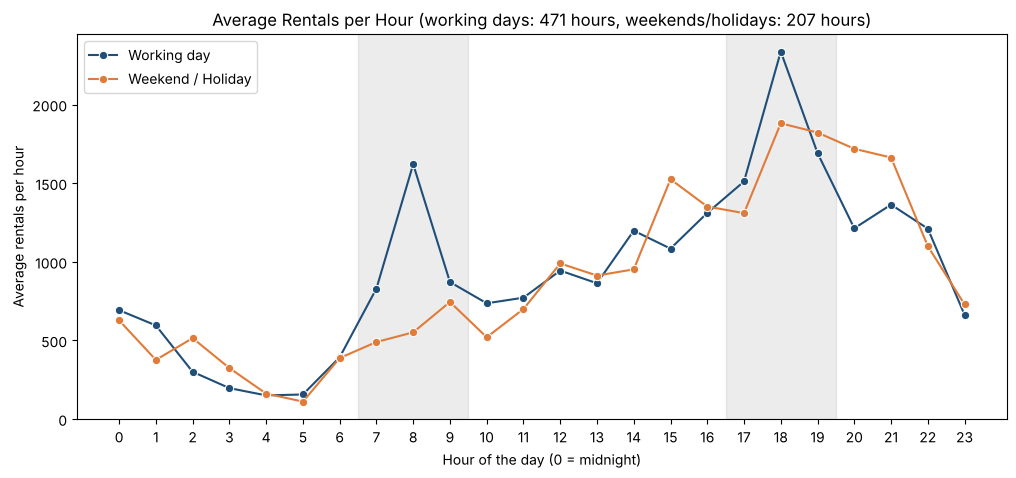

In [7]:
# number of observed hours for each day type (shown in the legend)
hours_count = bikes['day_type'].value_counts()


# setting the plot size
fig, ax = plt.subplots(figsize = (12, 5))


# average rentals for each hour of the day, working days vs weekends/holidays
sns.lineplot(x        = 'Hour',
             y        = 'RENTALS',
             hue      = 'day_type',
             hue_order = ['Working day', 'Weekend / Holiday'],
             palette  = ['#1f4e79', '#e07b39'],
             data     = bikes,
             errorbar = None,
             marker   = 'o')


# shading the commute windows (7-9 am and 5-7 pm)
plt.axvspan(6.5, 9.5,   color = 'grey', alpha = 0.15)
plt.axvspan(16.5, 19.5, color = 'grey', alpha = 0.15)


# title, labels and legend
plt.title(label   = f"Average Rentals per Hour (working days: {hours_count['Working day']} hours, "
                    f"weekends/holidays: {hours_count['Weekend / Holiday']} hours)")
plt.xlabel(xlabel = 'Hour of the day (0 = midnight)')
plt.ylabel(ylabel = 'Average rentals per hour')
plt.xticks(ticks  = range(0, 24))
plt.legend(title  = '')
plt.show()

**What the hourly pattern shows**

* The chart compares working days (blue, 471 hours) with weekends and holidays (orange, 207 hours) at each hour of the day.
* On working days, demand rises sharply to about 1,620 rentals at 8 am and reaches its highest point, about 2,340 rentals, at 6 pm.
* Weekends and holidays, by contrast, have no morning peak; their demand builds slowly from late morning and stays high through the evening.
* At midday the two lines almost meet, so the gap between them is concentrated in the shaded commute hours, especially in the morning.
* Because each point averages only about 20 working-day hours or 9 off-day hours, single points are noisy, but the two-peak working-day shape is consistent across neighbouring hours.

In [8]:
# average rentals in the same clock hours, working days vs weekends/holidays
time_windows = {'8 am peak'          : [8],
                '6 pm peak'          : [18],
                'Morning, 7-9 am'    : [7, 8, 9],
                'Midday, 11 am-3 pm' : [11, 12, 13, 14, 15],
                'Evening, 5-7 pm'    : [17, 18, 19]}

window_table = pd.DataFrame()

for window, hours in time_windows.items():

    # average rentals for these hours, by day type
    averages = bikes[bikes['Hour'].isin(hours)].groupby('day_type')['RENTALS'].mean()
    window_table[window] = averages


# one row per window, plus the working-day / off-day ratio
window_table = window_table.T
window_table['Working / Off-day'] = window_table['Working day'] / window_table['Weekend / Holiday']

window_table.round({'Working day' : 0, 'Weekend / Holiday' : 0, 'Working / Off-day' : 2})

day_type,Weekend / Holiday,Working day,Working / Off-day
8 am peak,551.0,1620.0,2.94
6 pm peak,1881.0,2337.0,1.24
"Morning, 7-9 am",611.0,1087.0,1.78
"Midday, 11 am-3 pm",1042.0,991.0,0.95
"Evening, 5-7 pm",1661.0,1861.0,1.12


In [9]:
# does the morning pattern hold in every month?
mornings = bikes[bikes['Hour'].isin([7, 8, 9])]

by_month = mornings.pivot_table(index   = 'Month',
                                columns = 'day_type',
                                values  = 'RENTALS',
                                aggfunc = 'mean')


# working-day / off-day ratio for each month
by_month['Working / Off-day'] = by_month['Working day'] / by_month['Weekend / Holiday']

by_month.loc[['Mar', 'Apr', 'May', 'June']].round({'Working day' : 0, 'Weekend / Holiday' : 0, 'Working / Off-day' : 2})

day_type,Weekend / Holiday,Working day,Working / Off-day
Month,,,
Mar,355.0,681.0,1.92
Apr,628.0,940.0,1.49
May,537.0,1350.0,2.51
June,879.0,1529.0,1.74


**What the tables show**

* The first table compares the same clock hours on both day types: at 8 am working days are 2.94 times busier, while at 6 pm they are only 1.24 times busier.
* Over wider windows, working days are 1.78 times busier from 7 to 9 am and 1.12 times busier from 5 to 7 pm, but slightly quieter at midday (0.95).
* This suggests that the morning is driven by commuters, while in the evening leisure riders join the commuters on both day types.
* The second table repeats the morning comparison within each month, and the working-day ratio stays between 1.49 and 2.51.
* The commute pattern therefore holds in March, April, May and June, so it is not caused by a change in season.

<h3>Answer: Commuting</h3>

* Commuting fits the data best: at 8 am, working days have 2.9 times more rentals than weekends and holidays.
* This gap is specific to the commute hours, since working days are 1.8 times busier from 7 to 9 am and 1.1 times busier from 5 to 7 pm, while midday demand is about the same (0.95).
* The weekday morning increase is therefore consistent with commuting, although leisure trips may also take place on weekdays.
* The pattern is not a seasonal effect either, because working-day mornings are 1.5 to 2.5 times busier in each of the four months.
* Leisure is clearly present as well, since off-days are slightly busier at midday and stay busy late into the evening.
* External research is consistent with this conclusion, as member trips in Chicago's Divvy system are strongly associated with weekday morning and afternoon commuting periods (Lu et al., 2026, Abstract).
* Exercise, on the other hand, cannot be separated reliably from leisure or commuting, because the dataset has no trip-purpose labels.
* For the same reason, we cannot prove that more than half of all trips are commutes, but commuting is clearly the dominant pattern.
* Cook County should therefore plan bike availability around the working-day morning and evening peaks first.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part V: Task 2 - The Most Important Weather Factor (Linear Model)</h2>
* The weather columns use different scales, so we standardize them (mean 0, standard deviation 1) before comparing coefficients.
* A standardized coefficient shows how many rentals per hour change when a factor moves by one typical amount (one standard deviation).
* We compare three linear models: one with all weather columns, one without Dew Point, and one with weather plus hour, month and day type.

In [10]:
# how much of Dew Point can be explained by Temperature and Humidity together?
dew_model = LinearRegression()
dew_model.fit(bikes[['Temperature', 'Humidity']], bikes['Dew Point Temperature'])

dew_r2 = dew_model.score(bikes[['Temperature', 'Humidity']], bikes['Dew Point Temperature'])
print(f"Dew Point explained by Temperature and Humidity: {dew_r2:.0%}")

Dew Point explained by Temperature and Humidity: 97%


In [11]:
# standardizing the weather columns (mean 0, standard deviation 1)
weather_all    = weather + ['Dew Point Temperature']
scaler         = StandardScaler()
weather_scaled = pd.DataFrame(scaler.fit_transform(bikes[weather_all]), columns = weather_all)


# three linear models
x_dew      = weather_scaled                                    # 1. all weather columns
x_weather  = weather_scaled[weather]                           # 2. without Dew Point
x_controls = pd.concat([weather_scaled[weather], hour_dummies,  # 3. weather + hour, month and day type
                        month_dummies, bikes['offday']], axis = 1)

lm_dew, lm_weather, lm_controls = LinearRegression(), LinearRegression(), LinearRegression()


# fitting and scoring the three models
weather_results = [run_model(lm_dew,      x_dew,      y_rentals, '1. All weather (with Dew Point)'),
                   run_model(lm_weather,  x_weather,  y_rentals, '2. Weather without Dew Point'),
                   run_model(lm_controls, x_controls, y_rentals, '3. Weather + hour, month, day type')]

pd.DataFrame(weather_results)

,Model,Training R2,Testing R2,Train-Test Gap
0,1. All weather (with Dew Point),0.5173,0.5080,0.0093
1,2. Weather without Dew Point,0.5139,0.5031,0.0108
2,"3. Weather + hour, month, day type",0.7159,0.7301,0.0142


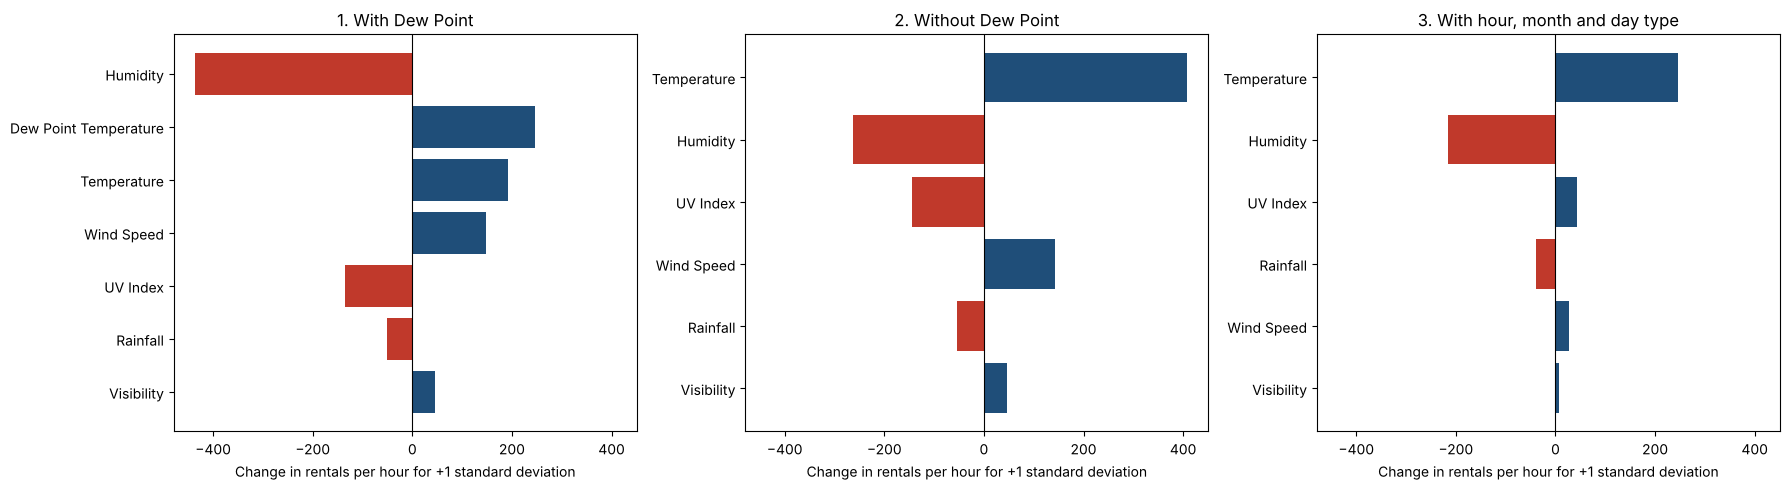

In [12]:
# standardized coefficients of the weather columns in each model
coef_dew      = pd.Series(lm_dew.coef_,      index = x_dew.columns)
coef_weather  = pd.Series(lm_weather.coef_,  index = x_weather.columns)
coef_controls = pd.Series(lm_controls.coef_, index = x_controls.columns)[weather]


# setting the plot size (three panels)
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (18, 5), sharex = True)


# one bar chart per model, largest effect on top
for axis, coefs, title in [(ax[0], coef_dew,      '1. With Dew Point'),
                           (ax[1], coef_weather,  '2. Without Dew Point'),
                           (ax[2], coef_controls, '3. With hour, month and day type')]:

    coefs = coefs.reindex(coefs.abs().sort_values().index)
    axis.barh(coefs.index, coefs.values, color = ['#c0392b' if value < 0 else '#1f4e79' for value in coefs.values])
    axis.axvline(0, color = 'black', linewidth = 0.8)
    axis.set_title(title)
    axis.set_xlabel('Change in rentals per hour for +1 standard deviation')


# displaying the plot
plt.tight_layout()
plt.show()

**What the weather coefficients show**

* Each bar shows how much rentals change for a typical change in that factor, so a longer bar means a bigger effect.
* In panel 1, humidity looks strongest, but this is misleading: temperature and humidity explain 97% of Dew Point, so the model splits their effects across overlapping columns.
* Once Dew Point is removed (panel 2), temperature clearly leads with +409 rentals per typical rise, compared with -263 for humidity.
* When hour, month and day type are held constant (panel 3), temperature still leads with +246, ahead of humidity with -215, although the gap narrows because month already captures part of the warming from March to June.
* Finally, UV Index changes from negative to positive once the hour is known, which suggests that its negative sign in panel 2 mostly reflected quiet middays.

In [13]:
# drop-one check: testing R-square lost when each weather factor is removed
drop_one = []

for factor in weather:

    # refitting each model without one factor
    without_weather  = run_model(LinearRegression(), x_weather.drop(columns = factor),  y_rentals, factor)
    without_controls = run_model(LinearRegression(), x_controls.drop(columns = factor), y_rentals, factor)

    # R-square lost compared with the full model
    drop_one.append({'Weather factor'          : factor,
                     'R2 lost (weather only)'  : weather_results[1]['Testing R2'] - without_weather['Testing R2'],
                     'R2 lost (with calendar)' : weather_results[2]['Testing R2'] - without_controls['Testing R2']})


# largest loss first
pd.DataFrame(drop_one).sort_values(by = 'R2 lost (weather only)', ascending = False).round(3)

,Weather factor,R2 lost (weather only),R2 lost (with calendar)
0,Temperature,0.299,0.022
1,Humidity,0.051,0.019
4,UV Index,0.023,0.002
2,Wind Speed,0.015,0.000
5,Rainfall,0.006,0.005
3,Visibility,0.001,0.000


In [14]:
# rain: average rentals and humidity in rainy and dry hours
# grouping hours by the rain flag (0 = dry, 1 = rain)
rain_table = bikes.groupby('rain').agg(hours           = ('RENTALS',  'count'),
                                       avg_rentals     = ('RENTALS',  'mean'),
                                       median_humidity = ('Humidity', 'median'))


# readable row names
rain_table.index = ['Dry hours', 'Rainy hours']
rain_table.round(0)

,hours,avg_rentals,median_humidity
Dry hours,618,1033.0,56.0
Rainy hours,60,116.0,96.0


**What the tables show**

* The model table shows that weather alone explains about half of the variation in rentals (test R-square of 0.50 to 0.51), while adding hour, month and day type raises it to 0.73.
* The drop-one table shows how much test R-square is lost when each factor is removed, and temperature causes the largest loss in both models (0.299 and 0.022).
* Humidity comes second (0.051 and 0.019), and in the model with the calendar it is almost as important as temperature.
* Wind, UV Index, rainfall and visibility each cost less than 0.03, so on their own they are weak planning signals.
* The rain table shows that rain still matters when it happens: rainy hours average 116 rentals against 1,033 in dry hours, and their median humidity is 96%.

<h3>Answer: Temperature, with humidity a close second</h3>

* Temperature is the most important weather factor, because it has the largest standardized coefficient in both models without Dew Point (+409 and +246 rentals per typical change).
* It also causes the largest loss in test R-square when it is removed, both in the weather-only model (0.299) and in the model with hour, month and day type (0.022).
* The regression tree in Task 3 points the same way, since its very first split is on temperature at 18.85 degrees.
* Humidity is a close second, especially once the calendar is known (a loss of 0.019 against 0.022), partly because humid air also signals wet weather, as rainy hours have a median humidity of 96%.
* Rain itself is severe but rare, with rainy hours averaging 116 rentals against 1,033 in dry hours, yet only 60 of the 678 hours had rain, so it explains less of the overall variation.
* In real-world terms, warmer weather in a cool spring makes riding more comfortable for commuters and leisure riders alike, which is a likely reason for temperature's strong effect.
* External research supports this rationale: in a study of urban cycling counts, ridership increased by 43% to 50% when temperature doubled, while temperature had a negative effect above 28 °C when humidity was above 60% (Miranda-Moreno & Nosal, 2011, Abstract).
* This means warming helps demand in spring but may stop helping on the hottest and most humid summer days, which this dataset does not cover.
* Cook County should therefore treat the temperature forecast as its main weather signal, while using the full model, which also includes humidity and rain, for hour-by-hour planning.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part VI: Task 3 - When Is Demand Low Enough for Maintenance? (Regression Tree)</h2>
* We build one pruned tree that uses only inputs known in advance: the hour, the weather, the day type and the month.
* We then take its quietest leaves until they cover at least 10% of the data, which is 68 hours.

In [15]:
# x-features for the maintenance tree (inputs known in advance)
tree_features = ['Hour', 'Temperature', 'Humidity', 'Wind Speed', 'Visibility',
                 'UV Index', 'Rainfall', 'offday', 'rush', 'month_num']


# comparing a few tree settings (depth and minimum samples per leaf)
tree_results = []

for depth, leaf in [(None, 1), (3, 8), (4, 8), (4, 25), (5, 8)]:

    tree = DecisionTreeRegressor(max_depth = depth, min_samples_leaf = leaf, random_state = 702)
    tree_results.append(run_model(tree, bikes[tree_features], y_rentals, f'depth {depth}, leaf {leaf}'))


# comparison of the settings
pd.DataFrame(tree_results)

,Model,Training R2,Testing R2,Train-Test Gap
0,"depth None, leaf 1",1.0000,0.5699,0.4301
1,"depth 3, leaf 8",0.6432,0.6340,0.0092
2,"depth 4, leaf 8",0.7465,0.7081,0.0384
3,"depth 4, leaf 25",0.6776,0.6366,0.0409
4,"depth 5, leaf 8",0.8022,0.7232,0.0790


**How we chose the tree settings**

* The table compares five tree settings on the same training and testing hours.
* The unpruned tree memorises the training data (training score 1.000) but scores only 0.570 on the test data, so it is badly overfit.
* A depth of 5 scores higher on the test data (0.723), but its gap of 0.079 is above the 0.05 rule.
* A depth of 4 with at least 8 hours per leaf has the best test score among the stable settings (0.708, gap 0.038).
* We therefore use this setting, which also keeps every path short enough to read as a simple rule.

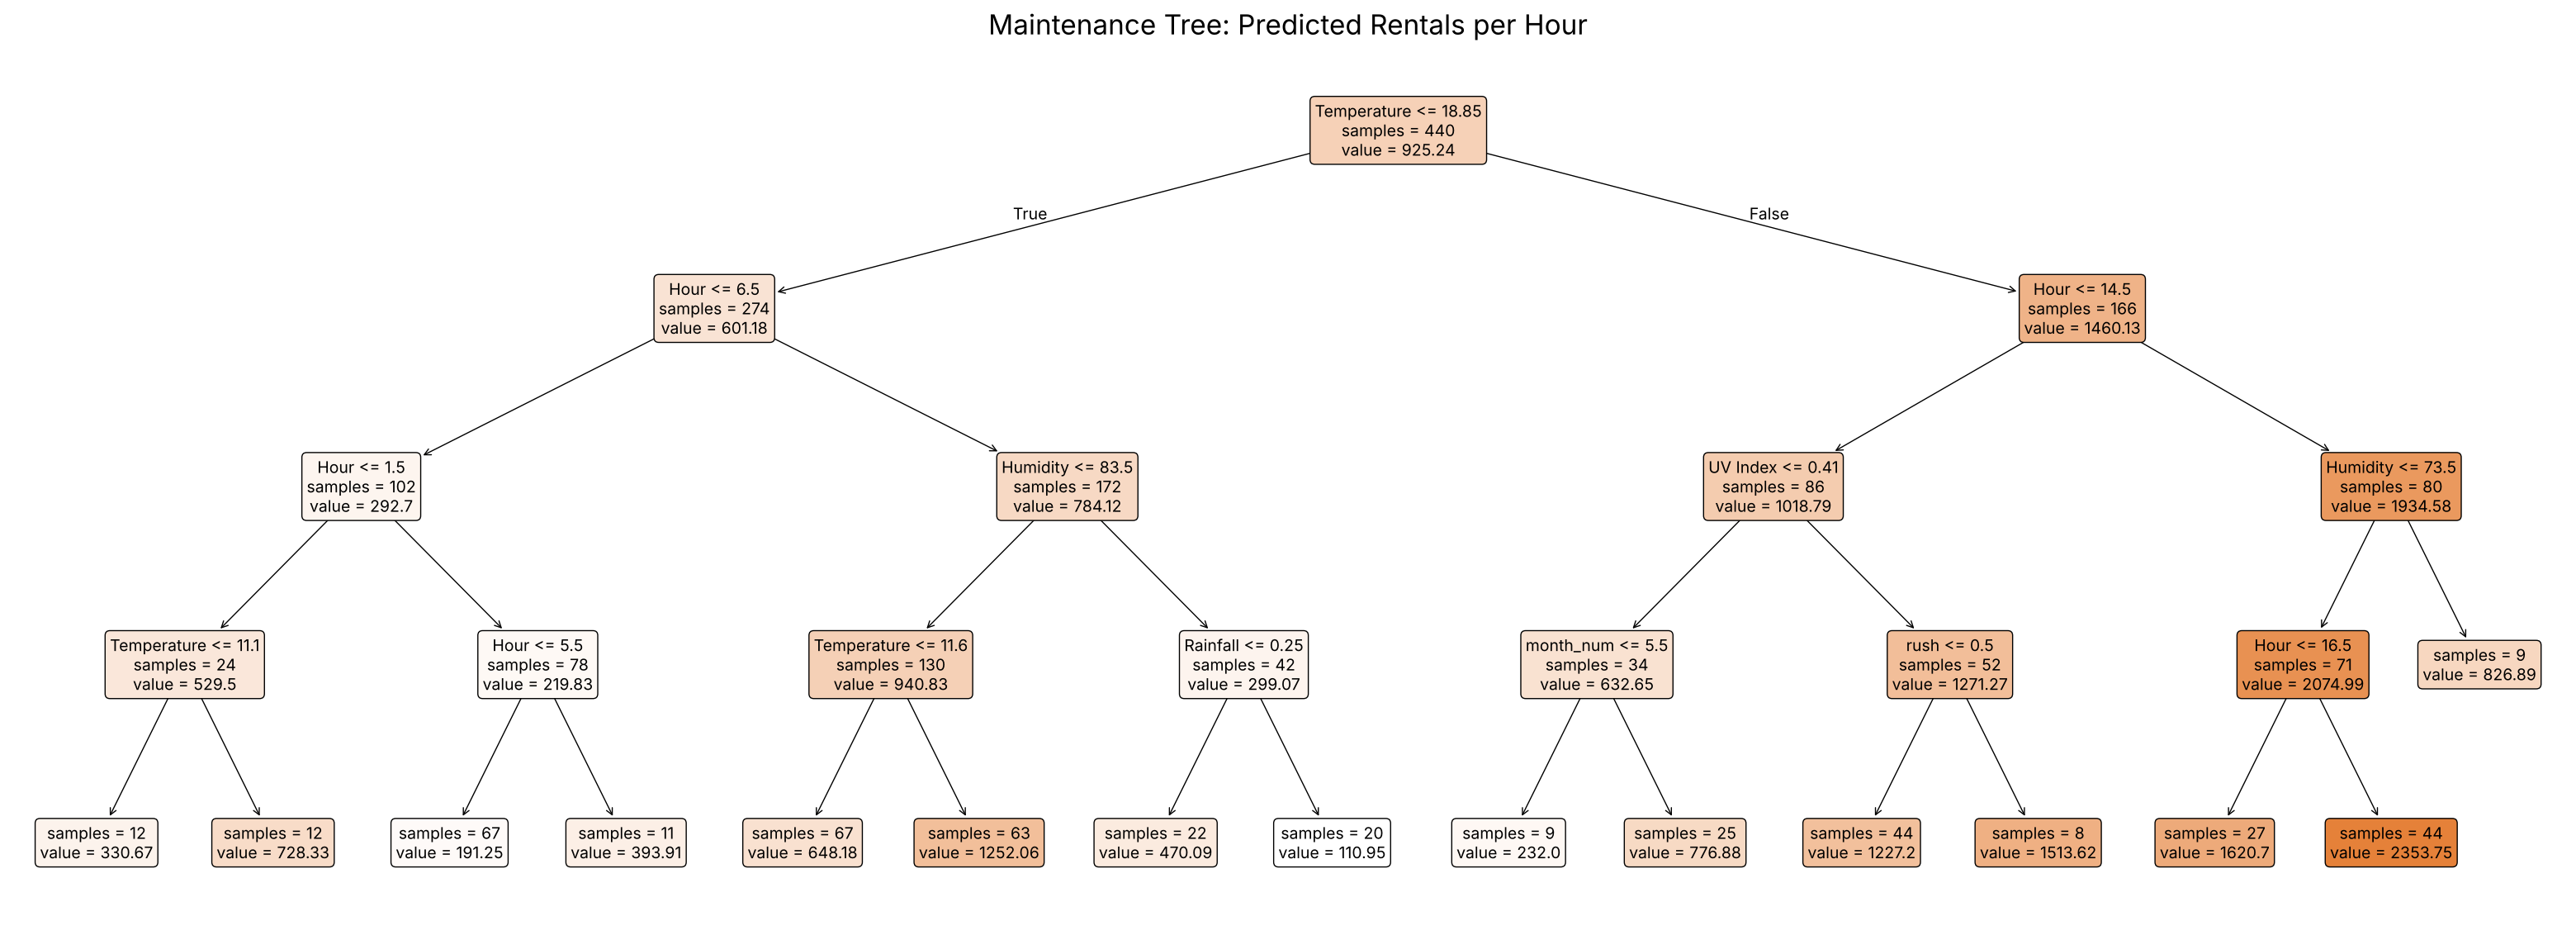

In [16]:
# the chosen maintenance tree: depth 4, at least 8 hours per leaf
maintenance_tree = DecisionTreeRegressor(max_depth = 4, min_samples_leaf = 8, random_state = 702)
run_model(maintenance_tree, bikes[tree_features], y_rentals, 'Maintenance tree')    # fits the tree on the training hours


# plotting the tree
plt.figure(figsize = (40, 14))

plot_tree(decision_tree = maintenance_tree,
          feature_names = tree_features,
          filled        = True,
          rounded       = True,
          impurity      = False,
          fontsize      = 14,
          precision     = 2)


# title and displaying the plot
plt.title('Maintenance Tree: Predicted Rentals per Hour', fontsize = 24)
plt.show()

**What the tree shows**

* The tree learns from 440 training hours and splits them into 15 groups (leaves), where darker boxes mean more rentals.
* Its first split is temperature at 18.85 degrees, which shows that cooler hours have lower demand.
* For these cool hours, the next split is the time of day, and the hours before 7 am are quiet, especially from 2 to 6 am.
* The quietest leaf contains cool, very humid (above 83.5%) hours with rain (above 0.25) from 7 am onward, whereas the busiest leaf contains warm, fairly dry hours from 5 pm onward, with about 2,350 rentals per hour.
* The tree is stable, with a training score of 0.746, a test score of 0.708 and a gap of 0.038.

In [17]:
# the two quietest leaves of the tree, written as filters on the full dataset
path_a = (bikes['Temperature'] <= 18.85) & (bikes['Hour'] >= 2) & (bikes['Hour'] <= 5)
path_b = (bikes['Temperature'] <= 18.85) & (bikes['Hour'] >= 7) & (bikes['Humidity'] > 83.5) & (bikes['Rainfall'] > 0.25)
both   = path_a | path_b                     # hours in either path


# hours covered, share of the dataset and average rentals for each path
maintenance = pd.DataFrame({'Hours'              : [path_a.sum(), path_b.sum(), both.sum()],
                            'Share of dataset %' : [path_a.mean() * 100, path_b.mean() * 100, both.mean() * 100],
                            'Avg rentals / hour' : [bikes.loc[path_a, 'RENTALS'].mean(),
                                                    bikes.loc[path_b, 'RENTALS'].mean(),
                                                    bikes.loc[both,   'RENTALS'].mean()]},
                           # one row per path, plus both paths together
                           index = ['Path A: cool nights, 2:00-5:59 am',
                                    'Path B: cool, very humid, rainy hours from 7 am',
                                    'Both paths together'])

maintenance.round(1)

,Hours,Share of dataset %,Avg rentals / hour
"Path A: cool nights, 2:00-5:59 am",93,13.7,190.7
"Path B: cool, very humid, rainy hours from 7 am",29,4.3,103.9
Both paths together,122,18.0,170.1


In [18]:
# demand outside the windows, share of all rentals inside them, and a check on the testing hours
train_rows, test_rows = train_test_split(bikes, test_size = 0.35, random_state = 702)
test_both = both[test_rows.index]            # which testing hours fall in the windows


# share of observed 2-6 am hours that are cool enough for Path A, by month
night = bikes[(bikes['Hour'] >= 2) & (bikes['Hour'] <= 5)]
cool_share = (night['Temperature'] <= 18.85).groupby(night['Month']).mean()


# printing the results

print(f"""
Average rentals outside the windows : {bikes.loc[~both, 'RENTALS'].mean():,.0f} per hour
Share of all rentals inside windows : {bikes.loc[both, 'RENTALS'].sum() / bikes['RENTALS'].sum():.1%}
Testing hours inside / outside      : {test_rows.loc[test_both, 'RENTALS'].mean():,.0f} vs {test_rows.loc[~test_both, 'RENTALS'].mean():,.0f} rentals per hour

Cool 2-6 am hours by month          : March {cool_share['Mar']:.0%}, April {cool_share['Apr']:.0%}, May {cool_share['May']:.0%}, June {cool_share['June']:.0%}
""")


Average rentals outside the windows : 1,123 per hour
Share of all rentals inside windows : 3.2%
Testing hours inside / outside      : 163 vs 1,146 rentals per hour

Cool 2-6 am hours by month          : March 100%, April 100%, May 88%, June 48%



**The selected maintenance windows**

* Path A covers cool nights from 2:00 to 5:59 am with a temperature of at most 18.85, and it includes 93 hours (13.7%) with about 191 rentals per hour.
* Path B covers cool, very humid, rainy hours from 7 am onward, and it includes 29 hours (4.3%) with about 104 rentals per hour.
* Together, the two paths cover 122 hours, or 18.0% of the data, which is well above the 68 hours needed for 10%.
* During these hours the system averages only 170 rentals, compared with 1,123 in all other hours, and the windows hold just 3.2% of all rentals.
* The pattern also holds on the testing hours, where the two paths average 163 rentals against 1,146 outside them.

<h3>Answer: Cool nights from 2 to 6 am, plus cool rainy hours (18% of the data)</h3>

* The tree identifies two low-demand paths, and both come from the same fitted tree.
* In Path A, from 2:00 to 5:59 am when the temperature is 18.85 or less, demand is about 190 rentals per hour, which covers 13.7% of the data.
* In Path B, from 7 am onward when it is cool, humidity is above 83.5% and it is raining, demand falls to about 100 rentals per hour, which adds another 4.3%.
* Together, the two paths cover 122 hours (18.0%) but only 3.2% of all rentals, so maintenance in these hours disturbs very few riders.
* This result also holds on the testing hours, where the two paths average 163 rentals against 1,146 outside them.
* We therefore recommend scheduling routine work, such as brake, tire and dock checks, from 2 to 6 am on cool nights.
* In this sample, the temperature condition held for all observed 2-6 am hours in March and April, 88% in May and 48% in June, so warmer June nights qualify less often.
* Cool rainy hours can serve as a backup window for bigger jobs, since the weather forecast shows them a day or two in advance.
* Even so, low demand does not guarantee safe working conditions or enough crew time, and the data has no autumn or winter months, so operations staff should confirm these windows.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part VII: Final Model - Real-Time Demand Prediction</h2>
* We compare seven candidate models on the same train-test split and choose the model with the highest test R-square among the models with a train-test gap of 0.05 or less.

In [19]:
# x-feature sets for the linear candidates
# benchmark: hour as one number
x_numeric_hour = pd.concat([bikes[weather + ['Hour', 'holiday', 'offday']], month_dummies], axis = 1)

# weather plus hour, month and day type
x_calendar     = pd.concat([bikes[weather + ['holiday', 'offday']], hour_dummies, month_dummies], axis = 1)

# adding the commute and weather flags
x_flags        = pd.concat([x_calendar, bikes[['rush', 'am_peak', 'pm_peak', 'rain', 'humid_high']]], axis = 1)

# adding the pleasant-evening flag (final feature set)
x_final        = pd.concat([x_flags, bikes['pleasant_evening']], axis = 1)


# fitting and scoring every candidate with the same split
final_model = LinearRegression()

candidates = [run_model(LinearRegression(), bikes[weather], y_rentals, 'Linear - weather only'),
              run_model(LinearRegression(), x_numeric_hour, y_rentals, 'Linear - hour as one number'),
              run_model(LinearRegression(), x_calendar,     y_rentals, 'Linear - weather + hour + month + day type'),
              run_model(LinearRegression(), x_flags,        y_rentals, 'Linear - + commute and weather flags'),
              run_model(final_model,        x_final,        y_rentals, 'Linear - + pleasant evening (FINAL)'),
              # the maintenance tree and an unpruned tree for comparison
              run_model(DecisionTreeRegressor(max_depth = 4, min_samples_leaf = 8, random_state = 702),
                        bikes[tree_features], y_rentals, 'Tree - depth 4, leaf 8'),
              run_model(DecisionTreeRegressor(random_state = 702),
                        bikes[tree_features], y_rentals, 'Tree - unpruned')]


# comparison table, best testing score first
comparison = pd.DataFrame(candidates)
comparison['Gap <= 0.05'] = comparison['Train-Test Gap'] <= 0.05
comparison.sort_values(by = 'Testing R2', ascending = False).round(3)

,Model,Training R2,Testing R2,Train-Test Gap,Gap <= 0.05
4,Linear - + pleasant evening (FINAL),0.790,0.827,0.037,True
3,Linear - + commute and weather flags,0.761,0.788,0.027,True
2,Linear - weather + hour + month + day type,0.716,0.730,0.014,True
5,"Tree - depth 4, leaf 8",0.746,0.708,0.038,True
1,Linear - hour as one number,0.592,0.580,0.011,True
6,Tree - unpruned,1.000,0.570,0.430,False
0,Linear - weather only,0.514,0.503,0.011,True


**How the models compare**

* All seven models use the same training and testing hours, so their scores can be compared fairly.
* Treating hour as one number (0-23) scores only 0.580, because demand has two daily peaks that a straight line cannot follow, whereas treating hour as categories lifts the model to 0.730.
* The unpruned tree, in contrast, fits the training data perfectly (1.000) but scores only 0.570 on the test data, so its gap of 0.430 fails the rule.
* Adding the commute and weather flags raises the test score to 0.788, and adding the pleasant-evening flag raises it further to 0.827, the best result of all candidates.
* The pleasant-evening flag comes from the Task 1 chart, where demand rises in the late afternoon and evening, and like the other flags it uses no powers, roots or rental values.
* The final model's gap of 0.037 is inside the 0.05 limit, and we use month instead of season because season is fully determined by month in this file.

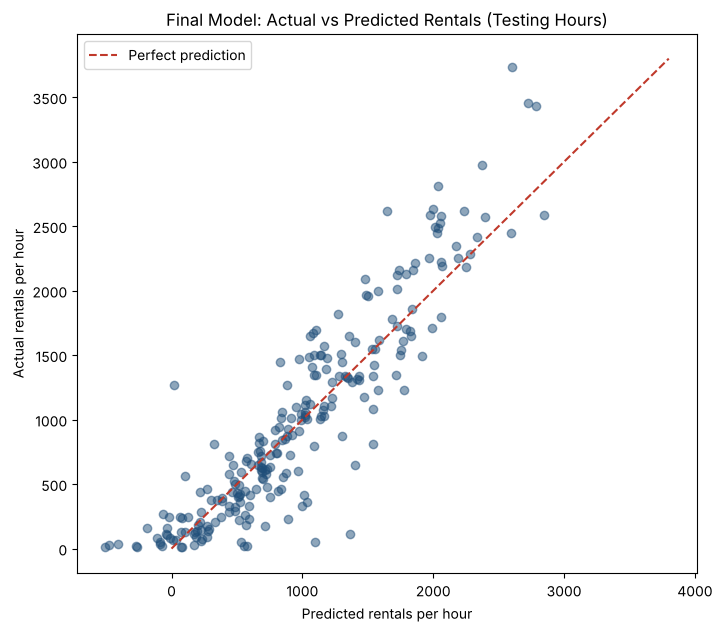


Average error           : 239 rentals per hour (median 156)
Average actual rentals  : 1,001 per hour
Busiest hours (> 1,500) : model predicts 276 too few on average
Negative predictions    : 16 of 238 testing hours



In [20]:
# predictions of the final model on the testing hours
x_train, x_test, y_train, y_test = train_test_split(x_final, y_rentals, test_size = 0.35, random_state = 702)
final_pred = final_model.predict(x_test)


# actual vs predicted rentals
fig, ax = plt.subplots(figsize = (8, 7))

plt.scatter(x = final_pred, y = y_test, alpha = 0.5, color = '#1f4e79')
plt.plot([0, 3800], [0, 3800], color = '#c0392b', linestyle = '--', label = 'Perfect prediction')

plt.title(label   = 'Final Model: Actual vs Predicted Rentals (Testing Hours)')
plt.xlabel(xlabel = 'Predicted rentals per hour')
plt.ylabel(ylabel = 'Actual rentals per hour')
plt.legend()
plt.show()


# size of the prediction errors
errors = y_test - final_pred
busy   = y_test > 1500

print(f"""
Average error           : {errors.abs().mean():,.0f} rentals per hour (median {errors.abs().median():,.0f})
Average actual rentals  : {y_test.mean():,.0f} per hour
Busiest hours (> 1,500) : model predicts {errors[busy].mean():,.0f} too few on average
Negative predictions    : {(final_pred < 0).sum()} of {len(final_pred)} testing hours
""")

**How accurate the predictions are**

* Each dot is one of the 238 test hours, and the closer a dot is to the red line, the better the prediction.
* Overall, the dots follow the line from quiet nights to busy evenings.
* The average error is 239 rentals per hour (median 156), while the average demand is about 1,000 rentals per hour.
* In the busiest hours (above 1,500 rentals), however, the model predicts about 276 rentals too few, so the County should keep some extra rebalancing capacity at peak times.
* Sixteen test hours also receive negative predictions, which is a known limit of linear models, so in practice any negative forecast should be read as zero.

In [21]:
# final model coefficients
coef = pd.Series(final_model.coef_, index = x_final.columns)


# translating the coefficients into business scenarios (change in rentals per hour)
scenarios = pd.Series({'Working day vs off-day, 8 am'       : coef['rush'] + coef['am_peak'] - coef['offday'],
                       'Working day vs off-day, 5-7 pm'     : coef['rush'] + coef['pm_peak'] - coef['offday'],
                       'Pleasant evening (15+, 4-11 pm)'    : coef['pleasant_evening'],
                       'Rain in the hour'                   : coef['rain'],
                       'Very humid hour (80% or more)'      : coef['humid_high'],
                       'June vs March'                      : coef['month_June']})

scenarios.round(0).to_frame('Change in rentals per hour')

,Change in rentals per hour
"Working day vs off-day, 8 am",914.0
"Working day vs off-day, 5-7 pm",-36.0
"Pleasant evening (15+, 4-11 pm)",601.0
Rain in the hour,-445.0
Very humid hour (80% or more),-260.0
June vs March,391.0


In [22]:
# example: a dry working-day 8 am hour in May at 14 degrees
example = pd.DataFrame(0.0, index = [0], columns = x_final.columns)

example[['Temperature', 'Humidity', 'Wind Speed', 'Visibility', 'UV Index', 'Rainfall']] = [14, 55, 1.5, 1800, 0.5, 0]
example[['hour_8', 'month_May', 'rush', 'am_peak']] = 1


# predicted rentals for this hour
print(f"Predicted rentals: {final_model.predict(example)[0]:,.0f}")

Predicted rentals: 1,640


<h3>Final model: linear regression (test R-square 0.827, gap 0.037)</h3>

* We recommend the linear model that combines weather, hour, month, day type, commute flags, weather flags and the pleasant-evening flag.
* It has the highest test R-square of all stable candidates (0.827) with a gap of 0.037, and it beats the best stable tree by 0.12.
* The model also turns into clear operating signals: holding the other inputs constant, an 8 am hour on a working day is associated with about 910 more rentals than the same hour on a weekend or holiday.
* Likewise, the pleasant-evening flag is associated with about 600 more rentals per hour, and once it is included, working-day and off-day evenings differ by only about 40 rentals.
* This suggests that the morning peak is driven by the work schedule, while the size of the evening peak depends mainly on comfortable weather.
* On the other side, the rain flag is associated with about 445 fewer rentals per hour and the high-humidity flag with about 260 fewer, while June runs about 390 rentals per hour above March.
* For example, a dry working-day 8 am hour in May at 14 degrees is predicted at about 1,640 rentals.
* For the next hour the model can use current weather readings, but planning a day ahead requires a weather forecast, which adds some extra error.
* Finally, because the model learned only from March to June, it should be monitored in use and retrained with data from the rest of the year.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part VIII: Recommendations for Cook County</h2>
**What the County can do now**

* The County should plan bike availability around the working-day peaks from 7 to 9 am and from 5 to 7 pm, when demand reaches about 1,620 and 2,340 rentals per hour.
* To set the daily fleet, the County should use the full demand forecast, with temperature as the main weather signal and humidity and rain as hour-by-hour adjustments.
* Routine maintenance should take place from 2 to 6 am on cool nights, and cool rainy hours can be used for bigger jobs, because together these windows hold only 3.2% of all rentals.
* Because the model under-predicts the busiest hours by about 276 rentals, the County should keep some extra rebalancing capacity during peak periods.
* The final model can already support these decisions hour by hour from March to June, as long as negative forecasts are read as zero and its errors are tracked.

**What needs more data**

* Before setting exact station targets or crew sizes, the County needs station-level demand, fleet size, staffing and cost data.
* The holiday coding, the UV Index column, the 0% humidity reading and the Rainfall value of 35 should also be checked at the source.
* In addition, data from July to February is needed so that the model and maintenance windows cover the whole year.
* Finally, a rider survey on trip purpose would measure commuting directly instead of inferring it from the time of day.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Modeling Rules Checklist</h2>
| Rule | How this notebook meets it |
|---|---|
| Model types | Only `LinearRegression()` and `DecisionTreeRegressor()` from scikit-learn (`StandardScaler` only rescales the weather columns in Task 2) |
| No polynomial or rooted x-variables | Only original columns, dummy variables and yes/no flags; no squares, roots, logs or exponents |
| y-variable not on the x-side | `RENTALS` is used only as y; no feature is built from it, and `ID` is excluded |
| Processing time | The notebook runs in a few seconds, well under 60 seconds |
| Error-free and commented | Runs from top to bottom without errors, with at least one comment for every five lines of code |
| Train-test gap ≤ 0.05 | Final model gap = 0.037 (training 0.790, test 0.827) |

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>References</h2>
Lu, J., Li, Z., & Guo, Q. (2026). Exploring the determinants of bike-sharing member trips with explainable machine learning: Insights from Chicago's Divvy system. *Computational Urban Science, 6*(1), Article 22. https://doi.org/10.1007/s43762-026-00254-9

Miranda-Moreno, L. F., & Nosal, T. (2011). Weather or not to cycle: Temporal trends and impact of weather on cycling in an urban environment. *Transportation Research Record, 2247*(1), 42-52. https://doi.org/10.3141/2247-06

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>AI Usage Acknowledgment</h2>
* I used Claude (Anthropic) to explore the data, draft code and text, and find external sources.
* I used ChatGPT / Codex (OpenAI) to review the notebook and suggest changes to the code and wording.
* I directed the analysis: I asked for simple class-style code, checked the results, chose the final writing style, and verified every number against the notebook output.
* My full prompts and the AI responses are available in the Claude conversation: https://claude.ai/code/session_01QLm5fZMB4zAeoMvbg6bBPU